# Do the scores and rebates explain the behavior?

I first check the rebate rates among recorded claimants. Then I ask whether the positive Banker score follows the physical hand number or the position in the supplied score file.

In [1]:
from pathlib import Path

import duckdb

database = Path("../private/wagers.duckdb")
con = duckdb.connect(str(database), read_only=True, config={"threads": 4, "memory_limit": "3GB"})

In [2]:
con.sql('''
    SELECT count(*) AS recorded_claimants,
           round(median(avg_rebate_pcnt), 2) AS median_rate_as_stored,
           round(max(avg_rebate_pcnt), 2) AS maximum_rate_as_stored
    FROM rebates
''').df()

,recorded_claimants,median_rate_as_stored,maximum_rate_as_stored
0,16717,0.3,0.87


If the stored rates are percentages of turnover, the recorded maximum is below the observed loss rate for mirrored pair turnover. This is a rate comparison. Coverage of rebates, bonuses and withdrawal requirements remains open.

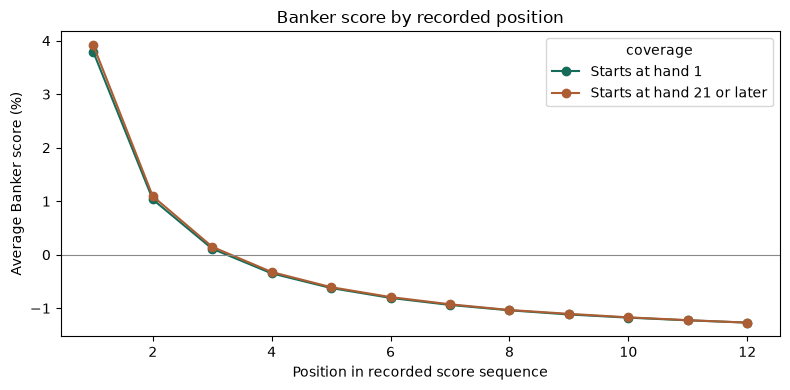

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

score_curve = con.sql('''
    WITH numbered AS (
        SELECT bank_beta, shoe_hand,
               min(shoe_hand) OVER shoe AS first_hand,
               row_number() OVER (PARTITION BY game, date, tableNO, shoe_ref ORDER BY shoe_hand) AS observed
        FROM scores
        WINDOW shoe AS (PARTITION BY game, date, tableNO, shoe_ref)
    ), grouped AS (
        SELECT *, CASE WHEN first_hand = 1 THEN 'Starts at hand 1'
                       WHEN first_hand >= 21 THEN 'Starts at hand 21 or later' END AS coverage
        FROM numbered WHERE observed <= 12
    )
    SELECT observed, coverage, avg(bank_beta) * 100 AS banker_score_pct
    FROM grouped WHERE coverage IS NOT NULL
    GROUP BY observed, coverage ORDER BY observed
''').df()

ax = score_curve.pivot(index="observed", columns="coverage", values="banker_score_pct").plot(
    marker="o", color=["#176c59", "#ac5d33"], figsize=(8, 4))
ax.axhline(0, color="#888888", linewidth=0.8)
ax.set(xlabel="Position in recorded score sequence", ylabel="Average Banker score (%)",
       title="Banker score by recorded position")
ax.get_figure().tight_layout()
plt.show()
con.close()

The score peaks on the first recorded hand even when the shoe starts late in the file. That makes the early values unsuitable as a standalone indicator of counting. This score file covers main bets in two variants and leaves side bets open.